# Bonus: read the component values (Digitize-HCD)
Read the text written next to each component (e.g. `1kΩ`, `5V`) and attach it to the right component.

**Pipeline**
1. Components: the YOLO11m detector from the main notebook.
2. Text boxes: Yolo11s, trained here.
3. Reading: TrOCR (`microsoft/trocr-base-handwritten`), fine-tuned on the dataset's text crops.
4. Matching: each text goes to the nearest component whose class fits the unit.

**How to run (Kaggle):** add two inputs: the Digitize-HCD dataset and `hcd-yolo-outputs` (the zip from the main notebook, with `best.pt` and `split.csv`). GPU T4, Internet On. Same split as the main notebook; all choices on validation, test once with `RUN_TEST = True`.

Order: 1 setup, 2 data, 3 matcher on ground truth, 4 reader zero-shot, 5 reader fine-tune, 6 text detector, 7 text detector on val, 8 full pipeline on val, 9 test (once), 10 example, 11 save.

## 1. Setup
Installs Ultralytics and `transformers` 4.57.6 (version 5 fails to load the TrOCR tokenizer; if transformers was already imported in this session, restart the kernel after the install). Finds the dataset, the component detector and the split from the main notebook (each path must match exactly one file). `COMP_CONF = 0.78` is the threshold chosen on validation there.

In [ ]:
!pip install -q ultralytics==8.4.182 transformers==4.57.6   # transformers 5.x cannot load the TrOCR tokenizer
import os, glob, json, random, shutil, datetime
import numpy as np, pandas as pd, cv2, torch, yaml
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

SEED = 42
RUN_TEST = True                       # True only for the final run
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

ANN = glob.glob("/kaggle/input/**/component_annotations.json", recursive=True)[0]
BASE = os.path.dirname(ANN)
IMG_DIR = os.path.join(BASE, "Circuit Diagram Images")
TXT_JSON = os.path.join(BASE, "text_annotations.json")
def find_one(pattern, prefer=""):
    """Exactly one match (preferring paths under `prefer`), otherwise stop with the list of matches."""
    hits = sorted(glob.glob(pattern, recursive=True))
    hits = [h for h in hits if prefer and h.startswith(prefer)] or hits
    assert len(hits) == 1, f"{pattern}: expected one file, found {hits}"
    return hits[0]

COMP_BEST = find_one("/kaggle/input/**/yolo11m_1024/weights/best.pt")
SPLIT_CSV = find_one("/kaggle/input/**/split.csv", prefer=COMP_BEST.split("/yolo11m_1024/")[0])   # the one next to best.pt
COMP_CONF = 0.78
WORK = "/kaggle/working"
os.makedirs(f"{WORK}/runs", exist_ok=True)     # figure and summary are saved here
print(BASE, COMP_BEST, SPLIT_CSV, sep="\n")

## 2. Load components, texts and the split
One table of component boxes and one of text boxes (`bbox` = `[x1, y1, x2, y2]`), each with the split of its image. Images missing from `split.csv` are dropped (the count is printed). Texts are short (about 3 characters): a number, a prefix and a unit, e.g. `1kΩ`, `2kHz`, `5μF`.

In [ ]:
stem = lambda p: os.path.splitext(os.path.basename(p))[0]
coco = json.load(open(ANN))
cats = {c["id"]: c["name"] for c in coco["categories"]}
id2stem = {im["id"]: stem(im["file_name"]) for im in coco["images"]}
stem2file = {stem(f): f for f in os.listdir(IMG_DIR)}

split = pd.read_csv(SPLIT_CSV)
split_of = {id2stem[i]: s for i, s in zip(split["image_id"], split["split"])}

comp_df = pd.DataFrame([(id2stem[a["image_id"]], cats[a["category_id"]], a["bbox"][0], a["bbox"][1],
                         a["bbox"][0] + a["bbox"][2], a["bbox"][1] + a["bbox"][3]) for a in coco["annotations"]],
                       columns=["stem", "cls", "x1", "y1", "x2", "y2"])

txt_json = json.load(open(TXT_JSON))["data_list"]
img_size = {stem(im["file_name"]): (im["width"], im["height"]) for im in txt_json}
text_df = pd.DataFrame([(stem(im["file_name"]), i["text"], *i["bbox"]) for im in txt_json for i in im["instances"]],
                       columns=["stem", "text", "x1", "y1", "x2", "y2"])
text_df = text_df[(text_df.x2 > text_df.x1 + 1) & (text_df.y2 > text_df.y1 + 1)]     # drop empty boxes

for d in (comp_df, text_df):
    d["split"] = d["stem"].map(split_of)
print("text boxes without split or image (dropped):", int((text_df.split.isna() | ~text_df.stem.isin(stem2file)).sum()))
text_df = text_df[text_df.split.notna() & text_df.stem.isin(stem2file)]
comp_df = comp_df[comp_df.split.notna()]
print("vertical text boxes (taller than wide):", round(float(((text_df.y2 - text_df.y1) > (text_df.x2 - text_df.x1)).mean()), 4))
print("texts per split:", text_df.groupby("split").size().to_dict())
print("components per split:", comp_df.groupby("split").size().to_dict())

## 3. Matching rule, checked on the ground truth
The unit says which classes are possible: `Ω` → Resistor, `F` → Capacitor, `H` → Inductor, `Hz` or `sin/cos` → AC sources, `V` → voltage sources, `A` → current sources (`Hz` is checked before `H`). The text goes to the nearest possible component, measured as the gap between the two boxes. A text without a unit goes to the nearest component that can carry a value. Wire crossovers, diodes, transistors, op-amps and GND never get a value.

There is no text-component link in the dataset, so the matching cannot be scored directly. Instead, on ground-truth boxes (no detection or reading errors), texts that have a unit are matched by distance only (nearest component that can carry a value), and we check whether the chosen component's class fits the unit. This measures the geometric part of the rule at class level (not which of two neighbours of the same class), and also shows how often the unit rule changes the choice.

In [ ]:
UNIT_CLASSES = {"AC": {"V-AC", "I-AC"}, "Hz": {"V-AC", "I-AC"}, "Ω": {"Resistor"}, "F": {"Capacitor"},
                "H": {"Inductor"}, "V": {"V-DC", "V-DC (one port)", "V-AC"}, "A": {"I-DC", "I-AC"}}
VALUE_CLASSES = set().union(*UNIT_CLASSES.values())
DEFAULT_UNIT = {"Resistor": "Ω", "Capacitor": "F", "Inductor": "H", "V-DC": "V", "V-DC (one port)": "V", "I-DC": "A"}

def norm(t):
    return t.replace(" ", "").replace("µ", "μ").replace("Ω", "Ω")   # micro sign -> mu, ohm sign -> omega

def unit_of(text):
    t = norm(text)
    if "sin" in t or "cos" in t:
        return "AC"
    for u in ("Hz", "Ω", "F", "H", "V", "A"):
        if u in t:
            return u
    return None

def with_unit(text, cls):       # "1k" next to a resistor -> "1kΩ"
    return text if unit_of(text) or cls not in DEFAULT_UNIT else text + DEFAULT_UNIT[cls]

def box_gap(a, b):              # distance between two boxes, 0 if they touch
    dx = max(b[0] - a[2], a[0] - b[2], 0)
    dy = max(b[1] - a[3], a[1] - b[3], 0)
    return float(np.hypot(dx, dy))

def match_image(texts, comps, use_units=True):
    """texts: [(text, box)], comps: [(class, box)] -> index of the chosen component for each text (or None)"""
    out = []
    for text, tb in texts:
        u = unit_of(text) if use_units else None
        allowed = UNIT_CLASSES[u] if u else VALUE_CLASSES
        cands = [(box_gap(tb, cb), j) for j, (c, cb) in enumerate(comps) if c in allowed]
        out.append(min(cands)[1] if cands else None)
    return out

comp_by = dict(tuple(comp_df.groupby("stem")))
BOX = ["x1", "y1", "x2", "y2"]

def matcher_check(split):
    """Match ground-truth texts to ground-truth components, with and without the unit rule."""
    rows = []
    for s, t in text_df[text_df.split == split].groupby("stem"):
        c = comp_by.get(s, comp_df.iloc[:0])
        comps = list(zip(c.cls, c[BOX].values))
        texts = list(zip(t.text, t[BOX].values))
        for (text, _), a, b in zip(texts, match_image(texts, comps), match_image(texts, comps, use_units=False)):
            rows.append(dict(unit=unit_of(text), attached=a is not None,
                             dist_cls=comps[b][0] if b is not None else None, changed=a != b))
    r = pd.DataFrame(rows)
    u = r[r.unit.notna()]
    return {"texts": len(r), "with unit": round(len(u) / len(r), 3),
            "attached": round(r.attached.mean(), 3),
            "distance-only class fits unit": round(np.mean([d in UNIT_CLASSES[k] for d, k in zip(u.dist_cls, u.unit)]), 3),
            "unit changed the choice": round(r.changed.mean(), 3)}

ms_val = matcher_check("val")
print(ms_val)

## 4. Reader: crops and TrOCR without training
Each text box is cropped from the image (with 4 px of margin) and read by TrOCR. Plain boxes, no rotation: only about 0.5% of the labels are vertical (printed in section 2), and the text detector also returns plain boxes, so training and use see the same kind of crop.

**Metrics:** exact match (the whole string is right) and CER (character error rate: edits needed to fix the prediction, divided by the true length).

In [ ]:
from transformers import TrOCRProcessor, VisionEncoderDecoderModel
OCR_ID = "microsoft/trocr-base-handwritten"
processor = TrOCRProcessor.from_pretrained(OCR_ID)
ocr = VisionEncoderDecoderModel.from_pretrained(OCR_ID).to(DEVICE)
tok = processor.tokenizer

def load_rgb(s):
    return cv2.cvtColor(cv2.imread(os.path.join(IMG_DIR, stem2file[s])), cv2.COLOR_BGR2RGB)

def crop(img, b, pad=4):
    H, W = img.shape[:2]
    x1, y1, x2, y2 = [int(round(v)) for v in b]
    return img[max(y1 - pad, 0):min(y2 + pad, H), max(x1 - pad, 0):min(x2 + pad, W)].copy()

def make_crops(split):
    crops, labels = [], []
    for s, t in text_df[text_df.split == split].groupby("stem"):
        img = load_rgb(s)
        crops += [crop(img, b) for b in t[BOX].values]
        labels += list(t.text)
    return crops, labels

crops = {s: make_crops(s) for s in ("train", "val", "test")}
print({s: len(v[0]) for s, v in crops.items()})

def read_crops(images, bs=32):
    ocr.eval(); out = []
    for i in range(0, len(images), bs):
        pv = processor(images=[Image.fromarray(c) for c in images[i:i + bs]], return_tensors="pt").pixel_values.to(DEVICE)
        with torch.no_grad(), torch.autocast(DEVICE, dtype=torch.float16, enabled=DEVICE == "cuda"):
            ids = ocr.generate(pv, max_new_tokens=16)
        out += [norm(t) for t in processor.batch_decode(ids, skip_special_tokens=True)]
    return out

def edit_distance(a, b):
    d = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, d[0] = d[0], i
        for j, cb in enumerate(b, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, prev + (ca != cb))
    return d[len(b)]

def read_metrics(pred, gold):
    gold = [norm(g) for g in gold]
    return {"exact match": round(np.mean([p == g for p, g in zip(pred, gold)]), 3),
            "CER": round(sum(edit_distance(p, g) for p, g in zip(pred, gold)) / sum(len(g) for g in gold), 3)}

pred = read_crops(crops["val"][0])
print("zero-shot on val:", read_metrics(pred, crops["val"][1]))
print("examples (pred | true):", list(zip(pred[:15], crops["val"][1][:15])))

## 5. Fine-tune TrOCR on the training crops
3 epochs on the ~9,500 training crops (about 8 minutes each on a T4). The loss is computed here explicitly: with transformers 4.57 the built-in loss of this model shifts the labels a second time (the warning `loss_type=None ... ForCausalLMLoss`), which trains the model to predict two characters ahead. After each epoch the reader is scored on the validation crops and the best epoch is kept (decision on validation).

In [ ]:
EPOCHS, BS, LR = 3, 16, 5e-5
from transformers.models.vision_encoder_decoder.modeling_vision_encoder_decoder import shift_tokens_right
OCR_DIR = f"{WORK}/trocr_values"
if ocr.config.decoder_start_token_id is None: ocr.config.decoder_start_token_id = tok.cls_token_id
if ocr.config.pad_token_id is None: ocr.config.pad_token_id = tok.pad_token_id

class CropDS(torch.utils.data.Dataset):
    def __init__(self, images, labels): self.images, self.labels = images, labels
    def __len__(self): return len(self.images)
    def __getitem__(self, i):
        pv = processor(images=Image.fromarray(self.images[i]), return_tensors="pt").pixel_values[0]
        return pv, torch.tensor(tok(norm(self.labels[i]), max_length=24, truncation=True).input_ids)

def collate(batch):
    pv = torch.stack([b[0] for b in batch])
    labels = torch.nn.utils.rnn.pad_sequence([b[1] for b in batch], batch_first=True, padding_value=-100)
    return pv, labels

loader = torch.utils.data.DataLoader(CropDS(*crops["train"]), batch_size=BS, shuffle=True,
                                     num_workers=2, collate_fn=collate, generator=torch.Generator().manual_seed(SEED))
opt = torch.optim.AdamW(ocr.parameters(), lr=LR)
scaler = torch.amp.GradScaler("cuda")
best_em, history = -1, []
for epoch in range(1, EPOCHS + 1):
    ocr.train(); t0 = datetime.datetime.now(); losses = []
    for pv, labels in loader:
        labels = labels.to(DEVICE)
        dec_in = shift_tokens_right(labels, ocr.config.pad_token_id, ocr.config.decoder_start_token_id)  # shift once
        with torch.autocast("cuda", dtype=torch.float16):
            logits = ocr(pixel_values=pv.to(DEVICE), decoder_input_ids=dec_in).logits
        loss = torch.nn.functional.cross_entropy(logits.float().reshape(-1, logits.size(-1)),
                                                 labels.reshape(-1), ignore_index=-100)
        opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        losses.append(loss.item())
    res = read_metrics(read_crops(crops["val"][0]), crops["val"][1])
    history.append({"epoch": epoch, "train loss": round(np.mean(losses), 4), **res})
    print(history[-1], "| time:", datetime.datetime.now() - t0)
    if res["exact match"] > best_em:
        best_em = res["exact match"]; ocr.save_pretrained(OCR_DIR); processor.save_pretrained(OCR_DIR)

del opt, scaler, loader, ocr; torch.cuda.empty_cache()                   # free GPU memory for the YOLO models
ocr = VisionEncoderDecoderModel.from_pretrained(OCR_DIR).to(DEVICE)       # best epoch on validation
pred_val = read_crops(crops["val"][0])
read_val = read_metrics(pred_val, crops["val"][1])
print("fine-tuned on val:", read_val)
errors = [(p, norm(g)) for p, g in zip(pred_val, crops["val"][1]) if p != norm(g)]
print("some errors (pred | true):", errors[:20])

## 6. Text detector: single-class YOLO
Same recipe as the component detector (1024 px, same split, no flips), but a smaller model (`yolo11s`): one class with a simple shape, so a small model is enough and trains faster.

In [ ]:
TXT_OUT = f"{WORK}/text_yolo"
shutil.rmtree(TXT_OUT, ignore_errors=True)
for s in ("train", "val", "test"):
    os.makedirs(f"{TXT_OUT}/images/{s}"); os.makedirs(f"{TXT_OUT}/labels/{s}")
for s, t in text_df.groupby("stem"):
    sp, (W, H) = split_of[s], img_size[s]
    shutil.copy(os.path.join(IMG_DIR, stem2file[s]), f"{TXT_OUT}/images/{sp}/{stem2file[s]}")
    lines = []
    for x1, y1, x2, y2 in t[BOX].values:
        x1, y1, x2, y2 = max(x1, 0), max(y1, 0), min(x2, W), min(y2, H)
        lines.append(f"0 {(x1 + x2) / 2 / W:.6f} {(y1 + y2) / 2 / H:.6f} {(x2 - x1) / W:.6f} {(y2 - y1) / H:.6f}")
    open(f"{TXT_OUT}/labels/{sp}/{s}.txt", "w").write("\n".join(lines))
TXT_YAML = f"{TXT_OUT}/data.yaml"
yaml.safe_dump({"path": TXT_OUT, "train": "images/train", "val": "images/val", "test": "images/test",
                "names": {0: "text"}}, open(TXT_YAML, "w"), sort_keys=False)

txt_model = YOLO("yolo11s.pt")
txt_model.train(data=TXT_YAML, imgsz=1024, epochs=50, patience=15, batch=8, device=0, workers=4,
                fliplr=0.0, degrees=5, seed=SEED, deterministic=True,
                project=f"{WORK}/runs", name="text_yolo11s_1024", exist_ok=False, plots=True)
TEXT_BEST = f"{txt_model.trainer.save_dir}/weights/best.pt"
print(TEXT_BEST)

## 7. Text detector on validation
mAP of the text boxes, and the threshold `TEXT_CONF` chosen on validation (best F1), used later for the full pipeline.

In [ ]:
txt_model = YOLO(TEXT_BEST)
def text_eval(split):
    m = txt_model.val(data=TXT_YAML, split=split, imgsz=1024, batch=8, conf=0.001, device=0,
                      project=f"{WORK}/runs", name=f"text_{split}", exist_ok=True)
    return m, {"mAP50": round(float(m.box.map50), 4), "mAP50-95": round(float(m.box.map), 4),
               "P (best F1)": round(float(m.box.mp), 4), "R (best F1)": round(float(m.box.mr), 4)}

m_txt, det_val = text_eval("val")
f1 = m_txt.box.f1_curve.mean(0)
TEXT_CONF = float(np.linspace(0, 1, len(f1))[f1.argmax()])
print(det_val, "| TEXT_CONF =", round(TEXT_CONF, 3))

## 8. Full pipeline on validation
`read_circuit(path)` runs the three models and the matching rule on one image. Evaluated on all validation images against the ground-truth text:
- **found:** a predicted text box overlaps the true one (IoU ≥ 0.5);
- **found and read:** and the text is read exactly;
- **attached:** and it was given to a component (of a class that fits the unit; whether it is the *right* component is not checked, see section 3).

These are rates over the true texts (recall): extra predicted boxes are not penalised.

In [ ]:
comp_model = YOLO(COMP_BEST)

def read_circuit(path, comp_conf=COMP_CONF, text_conf=TEXT_CONF):
    """-> components [(class, box)], texts [dict(text, text_box, cls, comp_box, value)]"""
    bgr = cv2.imread(str(path))                     # YOLO expects BGR arrays
    img = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)      # TrOCR crops in RGB
    c = comp_model.predict(bgr, imgsz=1024, conf=comp_conf, device=0, verbose=False)[0].boxes
    comps = [(comp_model.names[int(k)], b) for k, b in zip(c.cls.cpu().numpy(), c.xyxy.cpu().numpy())]
    tb = txt_model.predict(bgr, imgsz=1024, conf=text_conf, device=0, verbose=False)[0].boxes.xyxy.cpu().numpy()
    texts = read_crops([crop(img, b) for b in tb]) if len(tb) else []
    links = match_image(list(zip(texts, tb)), comps)
    rows = [dict(text=t, text_box=b,
                 cls=comps[j][0] if j is not None else None,
                 comp_box=comps[j][1] if j is not None else None,
                 value=with_unit(t, comps[j][0]) if j is not None else None)
            for t, b, j in zip(texts, tb, links)]
    return comps, rows

def iou_matrix(a, b):
    a, b = np.asarray(a, float).reshape(-1, 4), np.asarray(b, float).reshape(-1, 4)
    tl, br = np.maximum(a[:, None, :2], b[None, :, :2]), np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = np.clip(br - tl, 0, None).prod(2)
    area = lambda x: (x[:, 2] - x[:, 0]) * (x[:, 3] - x[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter + 1e-9)

def end_to_end(split):
    n = found = read_ok = attached = 0
    for s, gt in text_df[text_df.split == split].groupby("stem"):
        _, rows = read_circuit(os.path.join(IMG_DIR, stem2file[s]))
        iou = iou_matrix(gt[BOX].values, [r["text_box"] for r in rows])
        for i, g in enumerate(gt.text):
            n += 1
            if iou.shape[1] and iou[i].max() >= 0.5:
                r = rows[iou[i].argmax()]; found += 1
                if r["text"] == norm(g):
                    read_ok += 1; attached += r["cls"] is not None
    return {"texts": n, "found": round(found / n, 3), "found and read": round(read_ok / n, 3),
            "found, read and attached": round(attached / n, 3)}

e2e_val = end_to_end("val")
print(e2e_val)

## 9. Final evaluation on the test set (run once)
Only with `RUN_TEST = True`, after all choices are fixed (reader epoch, `TEXT_CONF`). Same four measurements as on validation.

In [ ]:
test_res = None
if RUN_TEST:
    assert not os.path.exists(f"{WORK}/TEST_DONE_values.txt"), "Test set already evaluated"
    test_res = {"matcher (ground truth)": matcher_check("test"),
                "reader (ground-truth crops)": read_metrics(read_crops(crops["test"][0]), crops["test"][1]),
                "text detector": text_eval("test")[1],
                "end to end": end_to_end("test")}
    open(f"{WORK}/TEST_DONE_values.txt", "w").write(f"{datetime.datetime.now()} text_conf={TEXT_CONF:.3f}")
    print(json.dumps(test_res, indent=2, ensure_ascii=False))
else:
    print("RUN_TEST = False: test set not evaluated")

## 10. Example
Components in green with their class; each value in red at its text, with a line to the component it was attached to. Change `path` to try your own image (for drawings that do not look like the dataset, a lower component threshold such as `comp_conf=0.25` helps). The reader only knows the dataset's labelling style: values without designators, so a label like `R1 4.7kΩ` is misread.

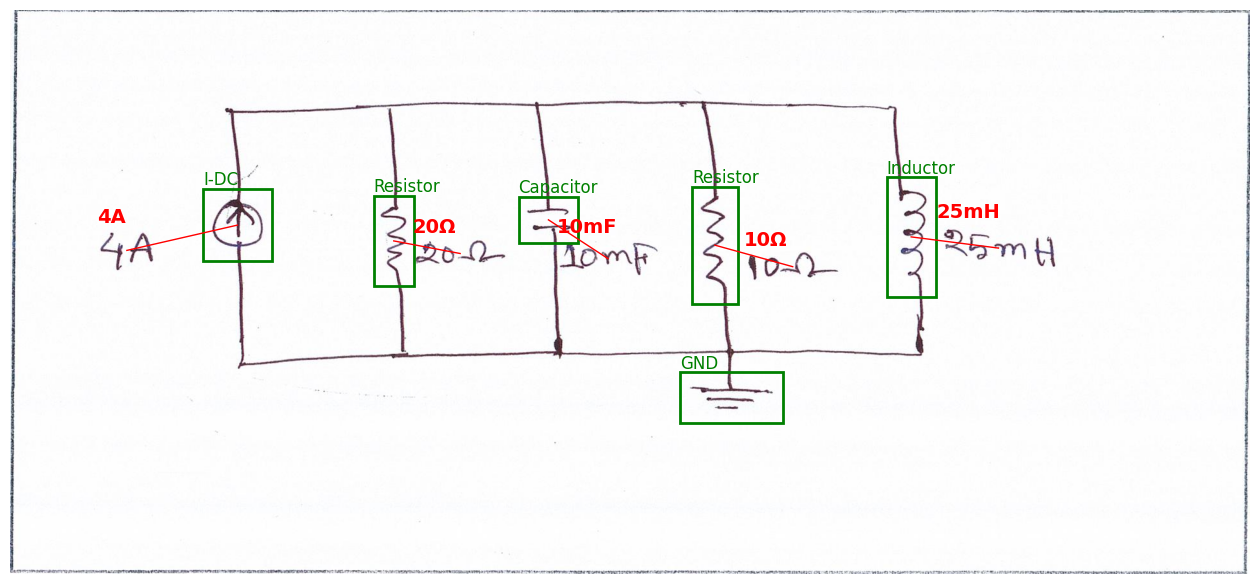

6 components, 5 texts read, 5 attached


In [15]:
path = os.path.join(IMG_DIR, stem2file[text_df[text_df.split == "val"].stem.iloc[0]])   # or your own image
comps, rows = read_circuit(path)          # own drawing: e.g. read_circuit(path, comp_conf=0.25)
img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(figsize=(16, 11)); ax.imshow(img); ax.axis("off")    # matplotlib can draw Ω and μ, cv2 cannot
for cls, (x1, y1, x2, y2) in comps:
    ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="green", lw=2))
    ax.text(x1, y1 - 6, cls, color="green", fontsize=12)
for r in rows:
    if r["value"]:
        (tx1, ty1, tx2, ty2), (cx1, cy1, cx2, cy2) = r["text_box"], r["comp_box"]
        ax.plot([(tx1 + tx2) / 2, (cx1 + cx2) / 2], [(ty1 + ty2) / 2, (cy1 + cy2) / 2], color="red", lw=1)
        ax.text(tx1, ty1 - 6, r["value"], color="red", fontsize=14, fontweight="bold")
fig.savefig(f"{WORK}/runs/example_values.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"{len(comps)} components, {len(rows)} texts read, {sum(r['value'] is not None for r in rows)} attached")

## 11. Save outputs
Metrics (`values_summary.json`), the test record, the example figure and the text detector runs in one zip. The fine-tuned reader is in `/kaggle/working/trocr_values` (about 1.3 GB, download only if needed).

In [ ]:
summary = {"val": {"matcher (ground truth)": ms_val, "reader (ground-truth crops)": read_val,
                   "reader history": history, "text detector": det_val, "text_conf": TEXT_CONF,
                   "end to end": e2e_val},
           "test": test_res}
json.dump(summary, open(f"{WORK}/runs/values_summary.json", "w"), indent=2, ensure_ascii=False, default=float)
if os.path.exists(f"{WORK}/TEST_DONE_values.txt"):
    shutil.copy(f"{WORK}/TEST_DONE_values.txt", f"{WORK}/runs/")
shutil.make_archive(f"{WORK}/values_outputs", "zip", f"{WORK}/runs")